# NYC Yellow Taxi Longitudinal Analysis — 2015–2026

This notebook analyzes monthly trends in NYC Yellow Taxi data from January 2015 through August 2026.

The analysis focuses on long-term changes in:
- trip demand
- trip duration and distance
- travel speed
- total trip amounts
- airport pickups
- payment behavior

In [1]:
from pathlib import Path

import pandas as pd


summary_file = (
    Path.home()
    / "Data/processed/nyc-taxi/monthly_summary.parquet"
)

df = pd.read_parquet(summary_file)

df.head()

,year,month,trip_count,median_duration_min,median_distance_mi,median_speed_mph,median_total_amount,total_amount_sum,airport_pickup_share,credit_card_share
0,2015,1,12741035,9.950000,1.70,11.076923,11.16,1.925393e+08,3.783241,61.842323
1,2015,2,12442394,10.783333,1.70,10.350000,11.75,1.916597e+08,3.618540,64.151883
2,2015,3,13342951,10.916667,1.70,10.530165,11.80,2.115235e+08,4.169745,63.219426
3,2015,4,13063758,11.183333,1.76,10.531343,11.80,2.095369e+08,4.277651,62.583982
4,2015,5,13157677,11.383333,1.80,10.644518,12.30,2.161845e+08,4.624175,61.991535


In [2]:
df["period"] = pd.to_datetime(
    dict(
        year=df["year"],
        month=df["month"],
        day=1,
    )
)

df[["year", "month", "period"]].head()

,year,month,period
0,2015,1,2015-01-01
1,2015,2,2015-02-01
2,2015,3,2015-03-01
3,2015,4,2015-04-01
4,2015,5,2015-05-01


## 1. Long-term trip demand

We begin by examining how monthly Yellow Taxi trip volume changed between January 2015 and August 2026.

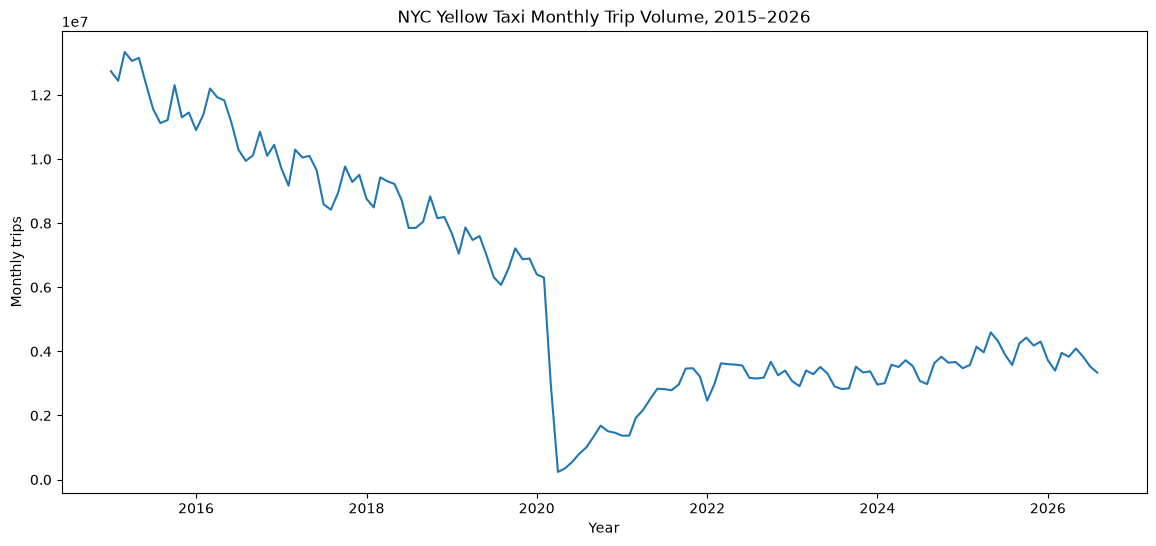

In [3]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["trip_count"],
)

ax.set_title("NYC Yellow Taxi Monthly Trip Volume, 2015–2026")
ax.set_xlabel("Year")
ax.set_ylabel("Monthly trips")

plt.show()

In [4]:
peak_row = df.loc[df["trip_count"].idxmax()]
low_row = df.loc[df["trip_count"].idxmin()]
latest_row = df.iloc[-1]

print(
    "Peak:",
    peak_row["period"].strftime("%Y-%m"),
    f"{peak_row['trip_count']:,}",
)

print(
    "Lowest:",
    low_row["period"].strftime("%Y-%m"),
    f"{low_row['trip_count']:,}",
)

print(
    "Latest:",
    latest_row["period"].strftime("%Y-%m"),
    f"{latest_row['trip_count']:,}",
)

Peak: 2015-03 13,342,951
Lowest: 2020-04 237,941
Latest: 2026-08 3,336,701


In [5]:
peak_count = peak_row["trip_count"]
low_count = low_row["trip_count"]
latest_count = latest_row["trip_count"]

peak_to_low_pct = (
    (low_count / peak_count) - 1
) * 100

latest_vs_peak_pct = (
    (latest_count / peak_count) - 1
) * 100

recovery_from_low_pct = (
    (latest_count / low_count) - 1
) * 100

print(
    f"Peak to low: {peak_to_low_pct:.1f}%"
)

print(
    f"Latest vs peak: {latest_vs_peak_pct:.1f}%"
)

print(
    f"Recovery from low: {recovery_from_low_pct:.1f}%"
)

Peak to low: -98.2%
Latest vs peak: -75.0%
Recovery from low: 1302.3%


In [6]:
jan_aug_2019 = df[
    (df["year"] == 2019)
    & (df["month"] <= 8)
]["trip_count"].mean()

jan_aug_2026 = df[
    (df["year"] == 2026)
    & (df["month"] <= 8)
]["trip_count"].mean()

change_pct = (
    (jan_aug_2026 / jan_aug_2019) - 1
) * 100

print(
    f"2019 Jan-Aug average: {jan_aug_2019:,.0f}"
)

print(
    f"2026 Jan-Aug average: {jan_aug_2026:,.0f}"
)

print(
    f"Change: {change_pct:.1f}%"
)

2019 Jan-Aug average: 7,129,831
2026 Jan-Aug average: 3,712,901
Change: -47.9%


### Key finding — Long-term trip demand

Yellow Taxi demand declined substantially even before the COVID-19 pandemic, falling from more than 12 million monthly trips in early 2015 to roughly 6–7 million by 2019.

The pandemic produced an exceptional disruption: monthly trip volume fell from a historical peak of 13.34 million trips in March 2015 to just 237,941 trips in April 2020, a decline of 98.2%.

Demand subsequently recovered strongly, but it has not returned to pre-pandemic levels. From January through August 2026, Yellow Taxis averaged 3.71 million trips per month compared with 7.13 million during the same months of 2019 - a decline of 47.9%.

This suggests that the post-pandemic recovery represents a stabilization at a structurally lower level of Yellow Taxi demand rather than a return to the volumes observed before 2020.

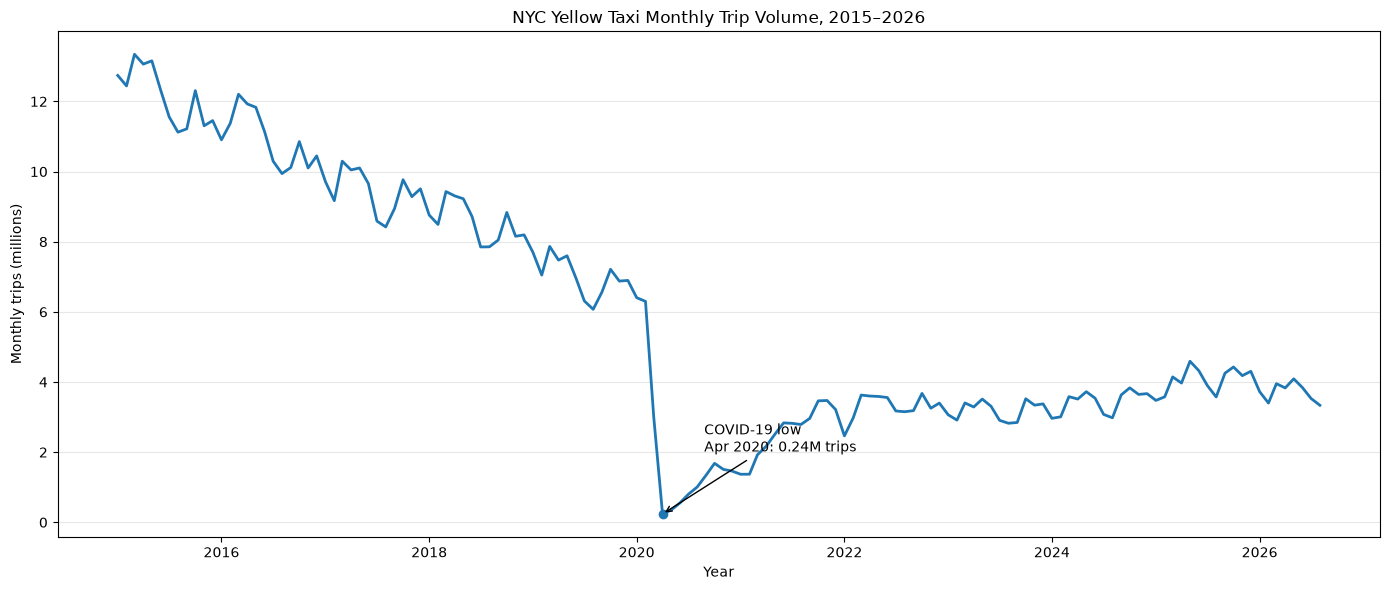

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["trip_count"] / 1_000_000,
    linewidth=2,
)

covid_low = df.loc[df["trip_count"].idxmin()]

ax.scatter(
    covid_low["period"],
    covid_low["trip_count"] / 1_000_000,
    zorder=3,
)

ax.annotate(
    "COVID-19 low\nApr 2020: 0.24M trips",
    xy=(
        covid_low["period"],
        covid_low["trip_count"] / 1_000_000,
    ),
    xytext=(30, 45),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)

ax.set_title(
    "NYC Yellow Taxi Monthly Trip Volume, 2015–2026"
)
ax.set_xlabel("Year")
ax.set_ylabel("Monthly trips (millions)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()

plt.show()

In [8]:
avg_2015 = df.loc[
    df["year"] == 2015,
    "trip_count",
].mean()

avg_2019 = df.loc[
    df["year"] == 2019,
    "trip_count",
].mean()

pre_covid_change_pct = (
    (avg_2019 / avg_2015) - 1
) * 100

print(f"2015 monthly average: {avg_2015:,.0f}")
print(f"2019 monthly average: {avg_2019:,.0f}")
print(f"2015 to 2019 change: {pre_covid_change_pct:.1f}%")

2015 monthly average: 12,169,936
2019 monthly average: 7,049,419
2015 to 2019 change: -42.1%


### Demand summary

Yellow Taxi demand was already in substantial decline before the COVID-19 pandemic. Average monthly trip volume fell from 12.17 million in 2015 to 7.05 million in 2019, a decline of 42.1%.

The pandemic then caused an extraordinary additional shock, with monthly trips falling to just 237,941 in April 2020.

Although trip volume recovered strongly afterward, January–August 2026 still averaged only 3.71 million trips per month, 47.9% below the same period in 2019.

The data therefore indicates two distinct phases: a structural decline before 2020, followed by a pandemic shock and a partial recovery to a persistently lower demand level.

## 2. Trip characteristics over time

This section examines how the typical characteristics of Yellow Taxi trips changed between 2015 and 2026.

We focus on:
- median trip duration
- median trip distance
- median trip speed

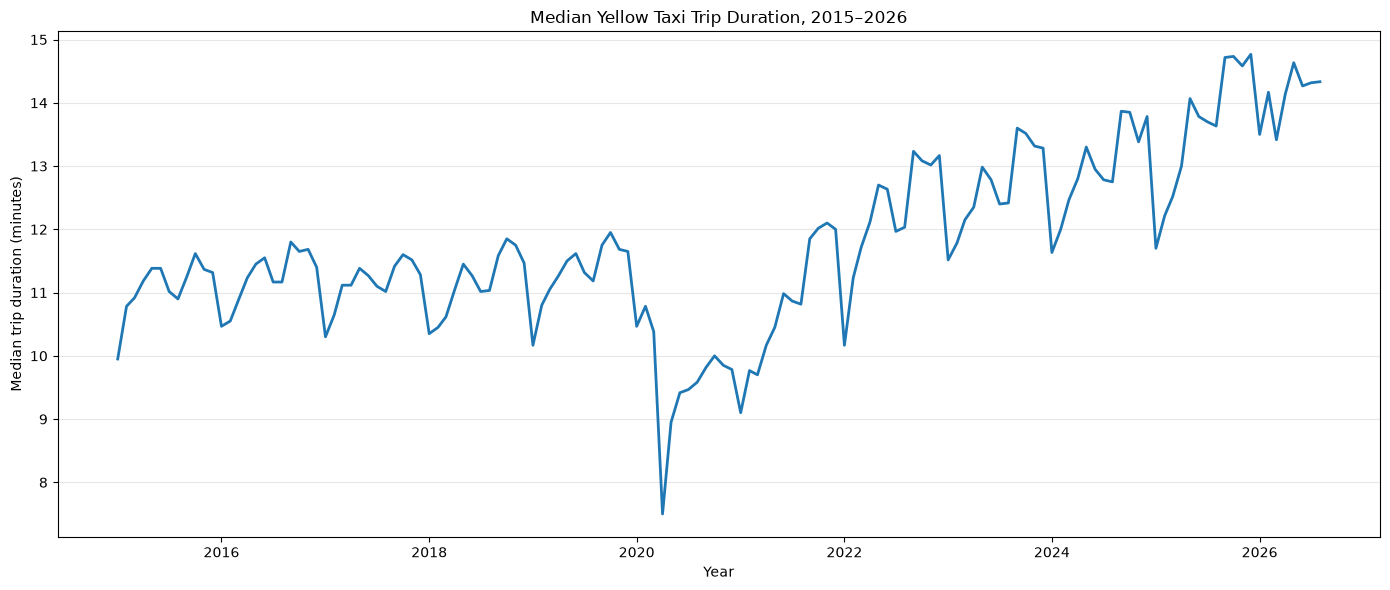

In [9]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["median_duration_min"],
    linewidth=2,
)

ax.set_title(
    "Median Yellow Taxi Trip Duration, 2015–2026"
)
ax.set_xlabel("Year")
ax.set_ylabel("Median trip duration (minutes)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()

plt.show()

In [10]:
avg_duration_2015 = df.loc[
    df["year"] == 2015,
    "median_duration_min",
].mean()

avg_duration_2019 = df.loc[
    df["year"] == 2019,
    "median_duration_min",
].mean()

avg_duration_2026 = df.loc[
    (df["year"] == 2026)
    & (df["month"] <= 8),
    "median_duration_min",
].mean()

change_2015_2019 = (
    (avg_duration_2019 / avg_duration_2015) - 1
) * 100

change_2019_2026 = (
    (avg_duration_2026 / avg_duration_2019) - 1
) * 100

print(f"2015 average monthly median: {avg_duration_2015:.2f} min")
print(f"2019 average monthly median: {avg_duration_2019:.2f} min")
print(f"2026 Jan-Aug average monthly median: {avg_duration_2026:.2f} min")
print(f"2015 to 2019 change: {change_2015_2019:.1f}%")
print(f"2019 to 2026 change: {change_2019_2026:.1f}%")

2015 average monthly median: 11.09 min
2019 average monthly median: 11.33 min
2026 Jan-Aug average monthly median: 14.10 min
2015 to 2019 change: 2.2%
2019 to 2026 change: 24.4%


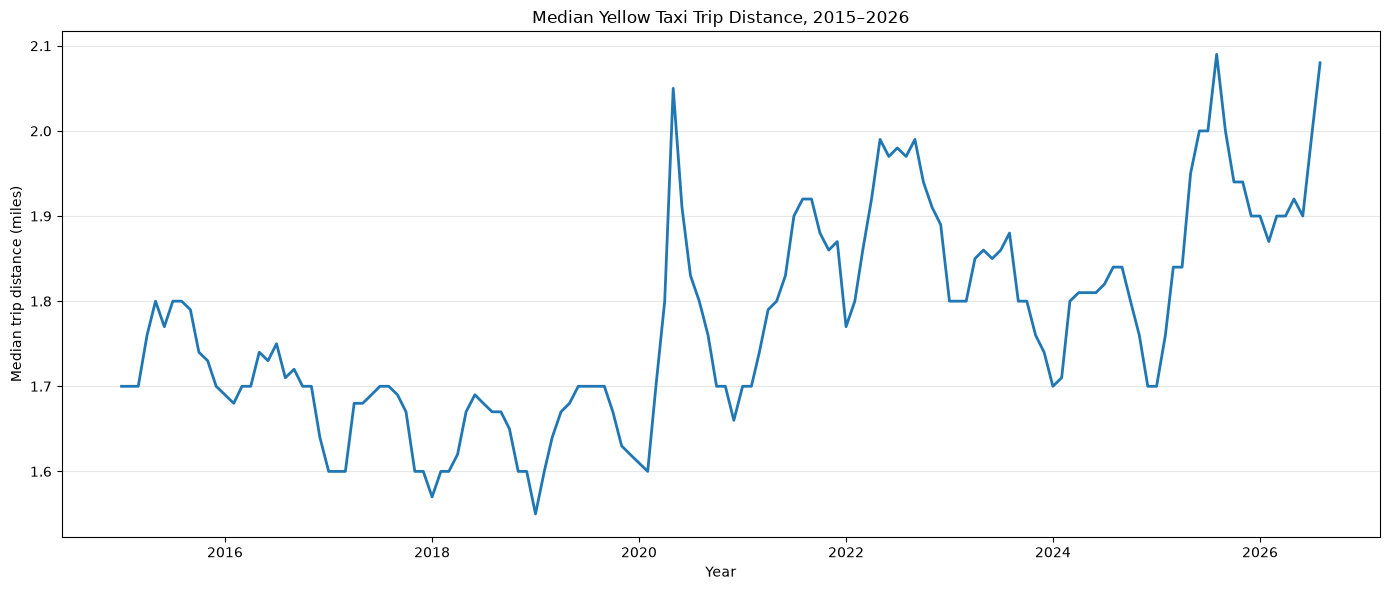

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["median_distance_mi"],
    linewidth=2,
)

ax.set_title(
    "Median Yellow Taxi Trip Distance, 2015–2026"
)
ax.set_xlabel("Year")
ax.set_ylabel("Median trip distance (miles)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()

plt.show()

In [12]:
avg_distance_2015 = df.loc[
    df["year"] == 2015,
    "median_distance_mi",
].mean()

avg_distance_2019 = df.loc[
    df["year"] == 2019,
    "median_distance_mi",
].mean()

avg_distance_2026 = df.loc[
    (df["year"] == 2026)
    & (df["month"] <= 8),
    "median_distance_mi",
].mean()

change_2015_2019 = (
    (avg_distance_2019 / avg_distance_2015) - 1
) * 100

change_2019_2026 = (
    (avg_distance_2026 / avg_distance_2019) - 1
) * 100

print(f"2015 average monthly median: {avg_distance_2015:.2f} mi")
print(f"2019 average monthly median: {avg_distance_2019:.2f} mi")
print(f"2026 Jan-Aug average monthly median: {avg_distance_2026:.2f} mi")
print(f"2015 to 2019 change: {change_2015_2019:.1f}%")
print(f"2019 to 2026 change: {change_2019_2026:.1f}%")

2015 average monthly median: 1.75 mi
2019 average monthly median: 1.66 mi
2026 Jan-Aug average monthly median: 1.93 mi
2015 to 2019 change: -5.4%
2019 to 2026 change: 16.8%


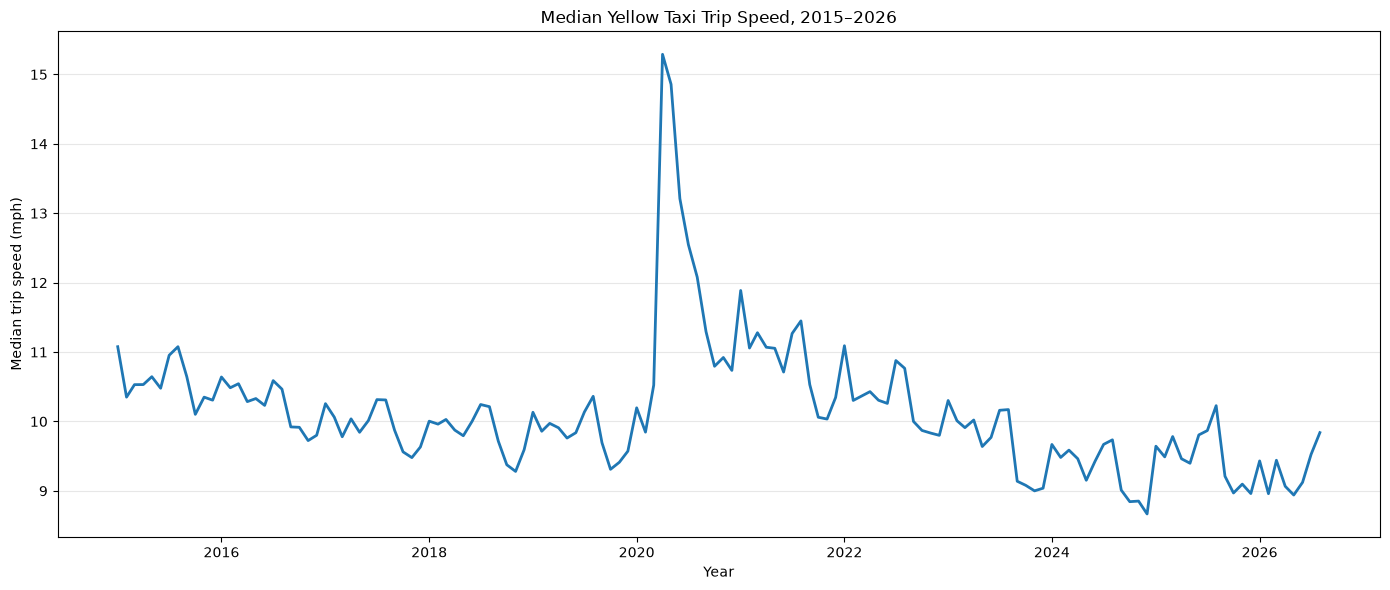

In [13]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["median_speed_mph"],
    linewidth=2,
)

ax.set_title(
    "Median Yellow Taxi Trip Speed, 2015–2026"
)
ax.set_xlabel("Year")
ax.set_ylabel("Median trip speed (mph)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()

plt.show()

In [14]:
avg_speed_2015 = df.loc[
    df["year"] == 2015,
    "median_speed_mph",
].mean()

avg_speed_2019 = df.loc[
    df["year"] == 2019,
    "median_speed_mph",
].mean()

avg_speed_2026 = df.loc[
    (df["year"] == 2026)
    & (df["month"] <= 8),
    "median_speed_mph",
].mean()

change_2015_2019 = (
    (avg_speed_2019 / avg_speed_2015) - 1
) * 100

change_2019_2026 = (
    (avg_speed_2026 / avg_speed_2019) - 1
) * 100

print(f"2015 average monthly median: {avg_speed_2015:.2f} mph")
print(f"2019 average monthly median: {avg_speed_2019:.2f} mph")
print(f"2026 Jan-Aug average monthly median: {avg_speed_2026:.2f} mph")
print(f"2015 to 2019 change: {change_2015_2019:.1f}%")
print(f"2019 to 2026 change: {change_2019_2026:.1f}%")

2015 average monthly median: 10.59 mph
2019 average monthly median: 9.83 mph
2026 Jan-Aug average monthly median: 9.29 mph
2015 to 2019 change: -7.2%
2019 to 2026 change: -5.5%


### Key finding — Trip characteristics

Typical Yellow Taxi trips have changed meaningfully over time.

Between 2019 and January–August 2026, the average monthly median trip duration increased from 11.33 to 14.10 minutes, a rise of 24.4%.

Over the same period, median trip distance increased from 1.66 to 1.93 miles (+16.8%), while median trip speed declined from 9.83 to 9.29 mph (-5.5%).

Together, these patterns suggest that the increase in trip duration is associated with both longer typical trips and somewhat lower travel speeds.

The pandemic period stands out as an exceptional temporary regime: trip volume collapsed, median trip duration fell sharply, and median speed increased substantially before gradually returning toward lower post-pandemic levels.

## 3. Fare and total amount trends

This section examines how the typical total trip amount and the aggregate monthly total amount changed between 2015 and 2026.

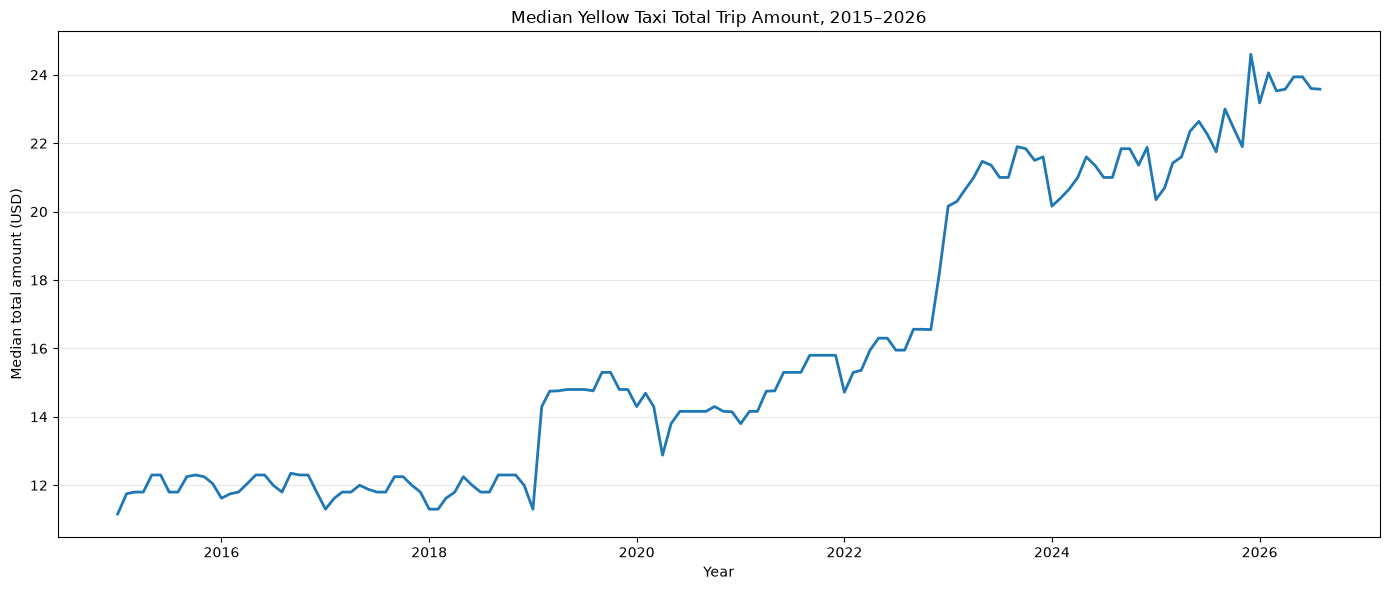

In [15]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["median_total_amount"],
    linewidth=2,
)

ax.set_title(
    "Median Yellow Taxi Total Trip Amount, 2015–2026"
)
ax.set_xlabel("Year")
ax.set_ylabel("Median total amount (USD)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()

plt.show()

In [16]:
avg_amount_2015 = df.loc[
    df["year"] == 2015,
    "median_total_amount",
].mean()

avg_amount_2019 = df.loc[
    df["year"] == 2019,
    "median_total_amount",
].mean()

avg_amount_2026 = df.loc[
    (df["year"] == 2026)
    & (df["month"] <= 8),
    "median_total_amount",
].mean()

change_2015_2019 = (
    (avg_amount_2019 / avg_amount_2015) - 1
) * 100

change_2019_2026 = (
    (avg_amount_2026 / avg_amount_2019) - 1
) * 100

print(f"2015 average monthly median: ${avg_amount_2015:.2f}")
print(f"2019 average monthly median: ${avg_amount_2019:.2f}")
print(f"2026 Jan-Aug average monthly median: ${avg_amount_2026:.2f}")
print(f"2015 to 2019 change: {change_2015_2019:.1f}%")
print(f"2019 to 2026 change: {change_2019_2026:.1f}%")

2015 average monthly median: $11.96
2019 average monthly median: $14.54
2026 Jan-Aug average monthly median: $23.68
2015 to 2019 change: 21.5%
2019 to 2026 change: 62.8%


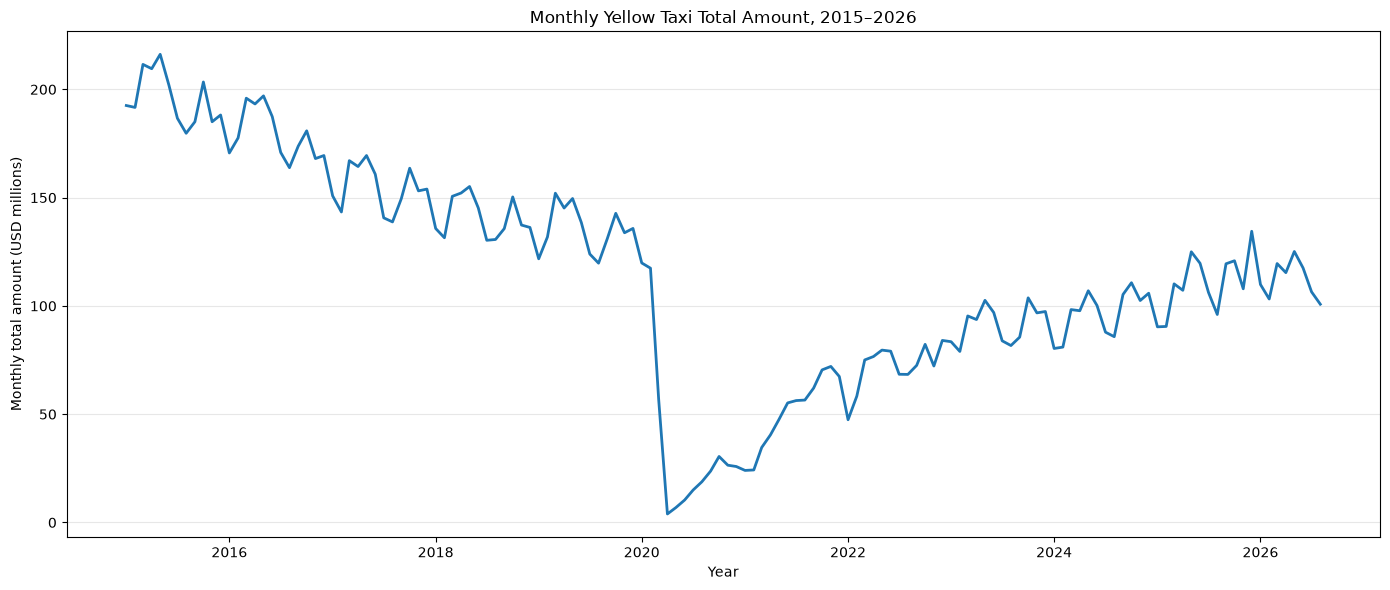

In [17]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["total_amount_sum"] / 1_000_000,
    linewidth=2,
)

ax.set_title(
    "Monthly Yellow Taxi Total Amount, 2015–2026"
)
ax.set_xlabel("Year")
ax.set_ylabel("Monthly total amount (USD millions)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()

plt.show()

In [18]:
avg_total_2015 = df.loc[
    df["year"] == 2015,
    "total_amount_sum",
].mean()

avg_total_2019 = df.loc[
    (df["year"] == 2019)
    & (df["month"] <= 8),
    "total_amount_sum",
].mean()

avg_total_2026 = df.loc[
    (df["year"] == 2026)
    & (df["month"] <= 8),
    "total_amount_sum",
].mean()

change_2019_2026 = (
    (avg_total_2026 / avg_total_2019) - 1
) * 100

print(
    f"2015 average monthly total amount: "
    f"${avg_total_2015 / 1_000_000:.1f}M"
)

print(
    f"2019 Jan-Aug average monthly total amount: "
    f"${avg_total_2019 / 1_000_000:.1f}M"
)

print(
    f"2026 Jan-Aug average monthly total amount: "
    f"${avg_total_2026 / 1_000_000:.1f}M"
)

print(
    f"2019 to 2026 change: "
    f"{change_2019_2026:.1f}%"
)

2015 average monthly total amount: $195.9M
2019 Jan-Aug average monthly total amount: $135.3M
2026 Jan-Aug average monthly total amount: $112.2M
2019 to 2026 change: -17.1%


### Key finding — Fare and total amount trends

The typical recorded trip amount increased substantially over time.

The average monthly median total amount rose from $14.54 in 2019 to $23.68 in January–August 2026, an increase of 62.8%.

However, aggregate monthly total amounts did not fully recover to pre-pandemic levels. Average monthly total amount for January–August declined from $135.3 million in 2019 to $112.2 million in 2026, a decrease of 17.1%.

This shows that higher amounts per trip have only partially offset the long-term decline in trip volume.

The values shown here are nominal and represent recorded total trip amounts, not inflation-adjusted fares or net driver/company revenue.

## 4. Airport pickup trends

This section examines how the share of Yellow Taxi trips originating at NYC-area airports changed between 2015 and 2026.

Airport pickups include JFK, LaGuardia (LGA), and Newark (EWR) taxi zones.

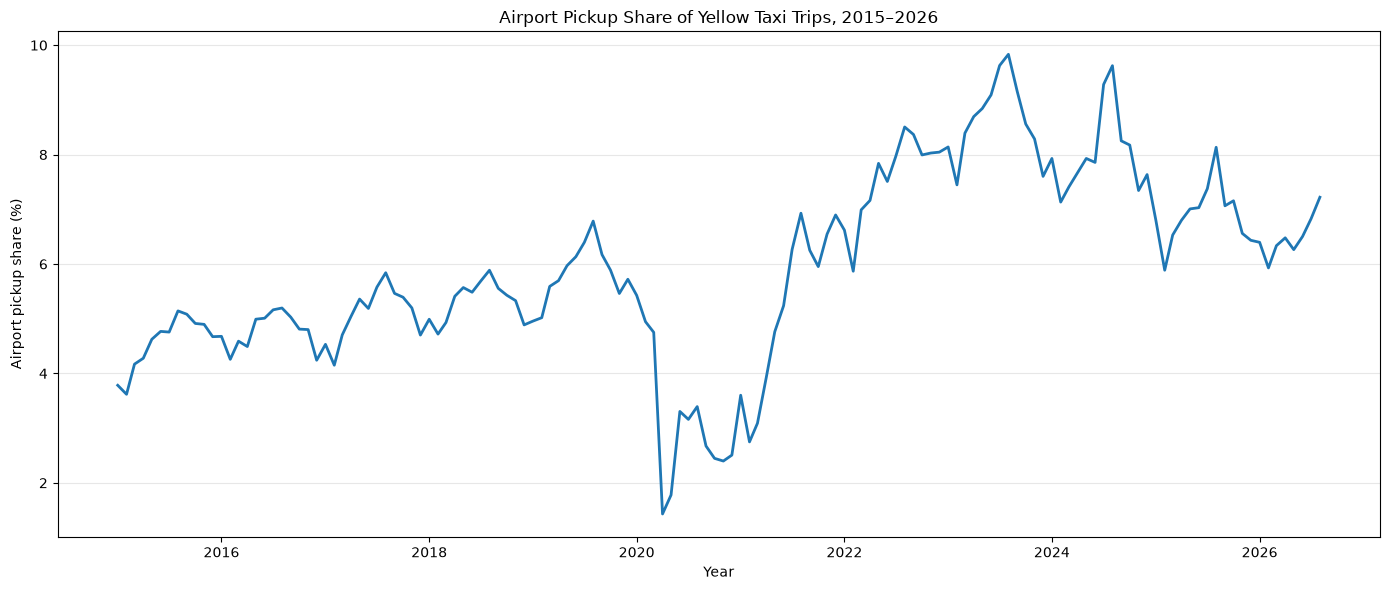

In [19]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["airport_pickup_share"],
    linewidth=2,
)

ax.set_title(
    "Airport Pickup Share of Yellow Taxi Trips, 2015–2026"
)
ax.set_xlabel("Year")
ax.set_ylabel("Airport pickup share (%)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()

plt.show()

In [20]:
avg_airport_2015 = df.loc[
    df["year"] == 2015,
    "airport_pickup_share",
].mean()

avg_airport_2019 = df.loc[
    df["year"] == 2019,
    "airport_pickup_share",
].mean()

avg_airport_2026 = df.loc[
    (df["year"] == 2026)
    & (df["month"] <= 8),
    "airport_pickup_share",
].mean()

change_2015_2019 = (
    (avg_airport_2019 / avg_airport_2015) - 1
) * 100

change_2019_2026 = (
    (avg_airport_2026 / avg_airport_2019) - 1
) * 100

print(f"2015 average airport pickup share: {avg_airport_2015:.2f}%")
print(f"2019 average airport pickup share: {avg_airport_2019:.2f}%")
print(f"2026 Jan-Aug average airport pickup share: {avg_airport_2026:.2f}%")
print(f"2015 to 2019 change: {change_2015_2019:.1f}%")
print(f"2019 to 2026 change: {change_2019_2026:.1f}%")

2015 average airport pickup share: 4.56%
2019 average airport pickup share: 5.82%
2026 Jan-Aug average airport pickup share: 6.49%
2015 to 2019 change: 27.6%
2019 to 2026 change: 11.7%


### Key finding — Airport pickups

Airport pickups have become a progressively larger component of Yellow Taxi activity.

The average airport pickup share increased from 4.56% in 2015 to 5.82% in 2019 and reached 6.49% in January–August 2026.

This represents a 27.6% relative increase between 2015 and 2019, followed by a further 11.7% increase between 2019 and 2026.

The pandemic temporarily disrupted this pattern, but airport pickups subsequently recovered to a larger share of total Yellow Taxi trips than before 2020.

Because overall Yellow Taxi trip volume is substantially lower than in earlier years, the higher share should be interpreted as increased relative importance within the Yellow Taxi trip mix, not necessarily as a higher absolute number of airport trips.

## 5. Payment behavior over time

This section examines how the share of Yellow Taxi trips paid by credit card changed between 2015 and 2026.

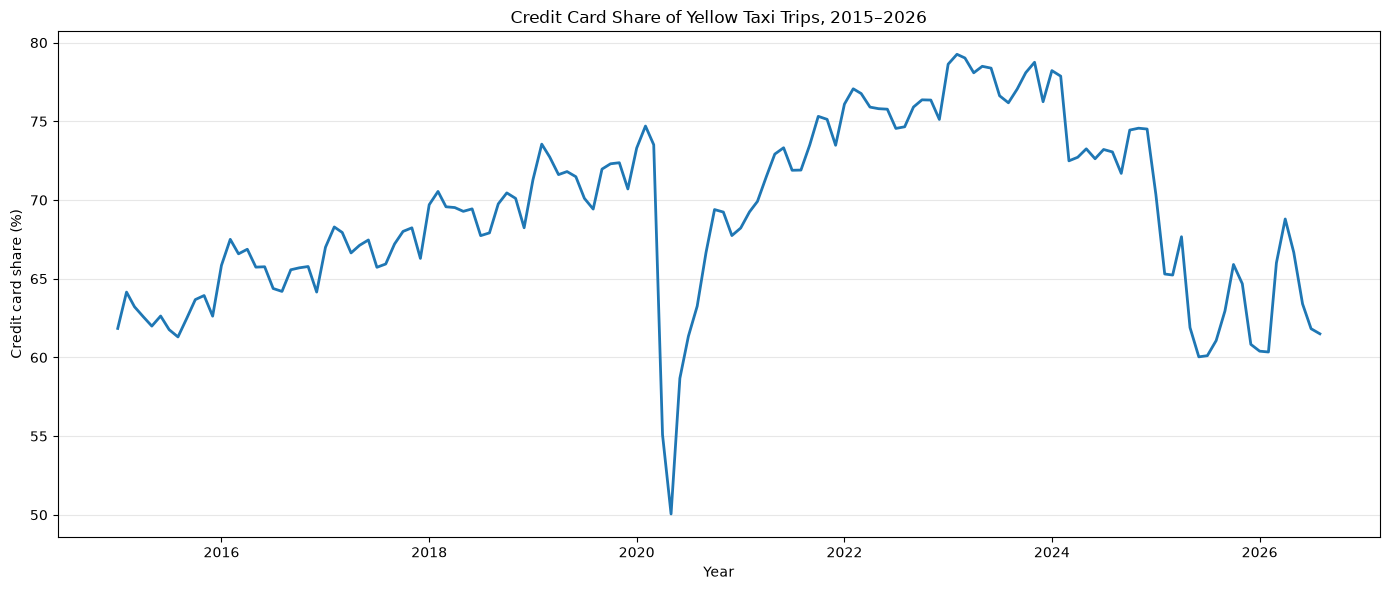

In [21]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["period"],
    df["credit_card_share"],
    linewidth=2,
)

ax.set_title(
    "Credit Card Share of Yellow Taxi Trips, 2015–2026"
)
ax.set_xlabel("Year")
ax.set_ylabel("Credit card share (%)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()

plt.show()

In [22]:
years_to_compare = [2015, 2019, 2023, 2024, 2025]

for year in years_to_compare:
    average_share = df.loc[
        df["year"] == year,
        "credit_card_share",
    ].mean()

    print(
        f"{year}: "
        f"{average_share:.2f}%"
    )

average_2026 = df.loc[
    (df["year"] == 2026)
    & (df["month"] <= 8),
    "credit_card_share",
].mean()

print(
    f"2026 Jan-Aug: "
    f"{average_2026:.2f}%"
)

2015: 62.68%
2019: 71.61%
2023: 77.90%
2024: 74.06%
2025: 63.84%
2026 Jan-Aug: 63.62%


In [23]:
from pathlib import Path

payment_periods = [
    "2024-12",
    "2025-01",
    "2026-01",
]

data_dir = (
    Path.home()
    / "Data/raw/nyc-taxi/yellow"
)

for period in payment_periods:
    year, month = period.split("-")

    file = (
        data_dir
        / year
        / f"yellow_tripdata_{period}.parquet"
    )

    payment_df = pd.read_parquet(
        file,
        columns=[
            "tpep_pickup_datetime",
            "payment_type",
        ],
    )

    valid_month = (
        (payment_df["tpep_pickup_datetime"].dt.year == int(year))
        & (payment_df["tpep_pickup_datetime"].dt.month == int(month))
    )

    payment_mix = (
        payment_df.loc[
            valid_month,
            "payment_type",
        ]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )

    print(f"\n{period}")
    print(payment_mix.round(2))


2024-12
payment_type
0     8.89
1    74.51
2    13.38
3     0.79
4     2.43
Name: proportion, dtype: float64

2025-01
payment_type
0    15.54
1    70.34
2    11.23
3     0.68
4     2.20
5     0.00
Name: proportion, dtype: float64

2026-01
payment_type
0    29.21
1    60.40
2     8.43
3     0.45
4     1.51
Name: proportion, dtype: float64


In [ ]:
payment_periods = [
    "2024-12",
    "2025-01",
    "2026-01",
]

for period in payment_periods:
    year, month = period.split("-")

    file = (
        data_dir
        / year
        / f"yellow_tripdata_{period}.parquet"
    )

    payment_df = pd.read_parquet(
        file,
        columns=[
            "tpep_pickup_datetime",
            "payment_type",
        ],
    )

    valid_month = (
        (payment_df["tpep_pickup_datetime"].dt.year == int(year))
        & (payment_df["tpep_pickup_datetime"].dt.month == int(month))
    )

    known_payment = payment_df.loc[
        valid_month
        & (payment_df["payment_type"] != 0)
    ]

    card_share_known = (
        (known_payment["payment_type"] == 1).mean()
        * 100
    )

    print(
        f"{period}: "
        f"{card_share_known:.2f}%"
    )

2024-12: 81.79%
2025-01: 83.28%


### Key finding — Payment behavior

Credit card usage increased substantially over most of the study period, with the average credit card share rising from 62.68% in 2015 to 77.90% in 2023.

From 2024 onward, however, the overall credit card share declined, reaching 63.84% in 2025 and 63.62% in January–August 2026.

This decline should not be interpreted simply as a shift away from card payments. The share of `payment_type = 0` (Flex Fare in the 2026 data) increased sharply, from 8.89% in December 2024 to 15.54% in January 2025 and 29.21% in January 2026.

Among trips outside the `payment_type = 0` category, credit cards became even more dominant: their share increased from 81.79% in December 2024 to 85.32% in January 2026.

The post-2024 change therefore appears to reflect a shift in the composition of payment categories, particularly the growing importance of Flex Fare, rather than a simple decline in card usage.

## 6. Longitudinal summary and key business insights

This section summarizes the most important long-term changes observed in NYC Yellow Taxi activity between 2015 and August 2026.

In [ ]:
summary_2015 = df[
    (df["year"] == 2015)
    & (df["month"] <= 8)
]

summary_2019 = df[
    (df["year"] == 2019)
    & (df["month"] <= 8)
]

summary_2026 = df[
    (df["year"] == 2026)
    & (df["month"] <= 8)
]

comparison = pd.DataFrame(
    {
        "Metric": [
            "Monthly trips",
            "Median duration (min)",
            "Median distance (mi)",
            "Median speed (mph)",
            "Median total amount (USD)",
            "Monthly total amount (USD M)",
            "Airport pickup share (%)",
            "Credit card share (%)",
        ],
        "2015 Jan-Aug": [
            summary_2015["trip_count"].mean(),
            summary_2015["median_duration_min"].mean(),
            summary_2015["median_distance_mi"].mean(),
            summary_2015["median_speed_mph"].mean(),
            summary_2015["median_total_amount"].mean(),
            summary_2015["total_amount_sum"].mean() / 1_000_000,
            summary_2015["airport_pickup_share"].mean(),
            summary_2015["credit_card_share"].mean(),
        ],
        "2019 Jan-Aug": [
            summary_2019["trip_count"].mean(),
            summary_2019["median_duration_min"].mean(),
            summary_2019["median_distance_mi"].mean(),
            summary_2019["median_speed_mph"].mean(),
            summary_2019["median_total_amount"].mean(),
            summary_2019["total_amount_sum"].mean() / 1_000_000,
            summary_2019["airport_pickup_share"].mean(),
            summary_2019["credit_card_share"].mean(),
        ],
        "2026 Jan-Aug": [
            summary_2026["trip_count"].mean(),
            summary_2026["median_duration_min"].mean(),
            summary_2026["median_distance_mi"].mean(),
            summary_2026["median_speed_mph"].mean(),
            summary_2026["median_total_amount"].mean(),
            summary_2026["total_amount_sum"].mean() / 1_000_000,
            summary_2026["airport_pickup_share"].mean(),
            summary_2026["credit_card_share"].mean(),
        ],
    }
)

comparison_display = comparison.copy()

comparison_display["2015 Jan-Aug"] = [
    f"{comparison.loc[0, '2015 Jan-Aug'] / 1_000_000:.2f}M",
    f"{comparison.loc[1, '2015 Jan-Aug']:.2f}",
    f"{comparison.loc[2, '2015 Jan-Aug']:.2f}",
    f"{comparison.loc[3, '2015 Jan-Aug']:.2f}",
    f"${comparison.loc[4, '2015 Jan-Aug']:.2f}",
    f"${comparison.loc[5, '2015 Jan-Aug']:.1f}M",
    f"{comparison.loc[6, '2015 Jan-Aug']:.2f}%",
    f"{comparison.loc[7, '2015 Jan-Aug']:.2f}%",
]

comparison_display["2019 Jan-Aug"] = [
    f"{comparison.loc[0, '2019 Jan-Aug'] / 1_000_000:.2f}M",
    f"{comparison.loc[1, '2019 Jan-Aug']:.2f}",
    f"{comparison.loc[2, '2019 Jan-Aug']:.2f}",
    f"{comparison.loc[3, '2019 Jan-Aug']:.2f}",
    f"${comparison.loc[4, '2019 Jan-Aug']:.2f}",
    f"${comparison.loc[5, '2019 Jan-Aug']:.1f}M",
    f"{comparison.loc[6, '2019 Jan-Aug']:.2f}%",
    f"{comparison.loc[7, '2019 Jan-Aug']:.2f}%",
]

comparison_display["2026 Jan-Aug"] = [
    f"{comparison.loc[0, '2026 Jan-Aug'] / 1_000_000:.2f}M",
    f"{comparison.loc[1, '2026 Jan-Aug']:.2f}",
    f"{comparison.loc[2, '2026 Jan-Aug']:.2f}",
    f"{comparison.loc[3, '2026 Jan-Aug']:.2f}",
    f"${comparison.loc[4, '2026 Jan-Aug']:.2f}",
    f"${comparison.loc[5, '2026 Jan-Aug']:.1f}M",
    f"{comparison.loc[6, '2026 Jan-Aug']:.2f}%",
    f"{comparison.loc[7, '2026 Jan-Aug']:.2f}%",
]

comparison_display

In [ ]:
total_trips = int(df["trip_count"].sum())

print(f"{total_trips:,}")

In [ ]:
from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Key points
peak = df.loc[df["trip_count"].idxmax()]
low = df.loc[df["trip_count"].idxmin()]
latest = df.loc[df["period"].idxmax()]

fig, ax = plt.subplots(figsize=(14, 7))

# Main trend
ax.plot(
    df["period"],
    df["trip_count"],
    linewidth=2.5,
)

ax.fill_between(
    df["period"],
    df["trip_count"],
    alpha=0.08,
)

# Highlight key observations
ax.scatter(
    peak["period"],
    peak["trip_count"],
    s=55,
    zorder=5,
)

ax.scatter(
    low["period"],
    low["trip_count"],
    s=55,
    zorder=5,
)

ax.scatter(
    latest["period"],
    latest["trip_count"],
    s=55,
    zorder=5,
)

# Historical peak annotation
ax.annotate(
    (
        f"Historical peak — {peak['period']:%b %Y}\n"
        f"{peak['trip_count'] / 1_000_000:.2f}M trips"
    ),
    xy=(peak["period"], peak["trip_count"]),
    xytext=(35, -35),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)

# COVID-19 low annotation
ax.annotate(
    (
        f"COVID-19 low — {low['period']:%b %Y}\n"
        f"{low['trip_count'] / 1_000_000:.2f}M trips"
    ),
    xy=(low["period"], low["trip_count"]),
    xytext=(35, 45),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)

# Latest observation annotation
ax.annotate(
    (
        f"{latest['period']:%b %Y}\n"
        f"{latest['trip_count'] / 1_000_000:.2f}M trips"
    ),
    xy=(latest["period"], latest["trip_count"]),
    xytext=(-85, 35),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    ha="center",
)

# Title and subtitle
ax.set_title(
    "NYC Yellow Taxi Monthly Trip Volume",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=20,
)

ax.text(
    0,
    1.02,
    "Monthly Yellow Taxi trips, January 2015 – August 2026",
    transform=ax.transAxes,
    fontsize=11,
)

# Axes
ax.set_xlabel("")
ax.set_ylabel("Monthly trips")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value / 1_000_000:.0f}M")
)

ax.xaxis.set_major_locator(
    mdates.YearLocator(2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

# Styling
ax.grid(
    axis="y",
    alpha=0.2,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.margins(x=0.01)

# Source
fig.text(
    0.01,
    0.01,
    "Source: NYC Taxi & Limousine Commission (TLC)",
    fontsize=9,
    alpha=0.7,
)

fig.tight_layout(
    rect=[0, 0.04, 1, 1]
)

# Save figure
output_file = figures_dir / "monthly_trip_volume.png"

fig.savefig(
    output_file,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Key points
first = df.loc[df["period"].idxmin()]
latest = df.loc[df["period"].idxmax()]

monthly_change = df["median_total_amount"].diff()
largest_jump = df.loc[monthly_change.idxmax()]
largest_jump_amount = monthly_change.max()

fig, ax = plt.subplots(figsize=(14, 7))

# Main trend
ax.plot(
    df["period"],
    df["median_total_amount"],
    linewidth=2.5,
)

ax.fill_between(
    df["period"],
    df["median_total_amount"],
    alpha=0.08,
)

# Highlight key observations
ax.scatter(
    first["period"],
    first["median_total_amount"],
    s=55,
    zorder=5,
)

ax.scatter(
    largest_jump["period"],
    largest_jump["median_total_amount"],
    s=55,
    zorder=5,
)

ax.scatter(
    latest["period"],
    latest["median_total_amount"],
    s=55,
    zorder=5,
)

# First observation annotation
ax.annotate(
    (
        f"{first['period']:%b %Y}\n"
        f"\\${first['median_total_amount']:.2f}"
    ),
    xy=(first["period"], first["median_total_amount"]),
    xytext=(35, 35),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)

# Largest monthly increase annotation
ax.annotate(
    (
        f"Largest monthly increase — {largest_jump['period']:%b %Y}\n"
        f"\\${largest_jump['median_total_amount']:.2f} "
        f"(+\\${largest_jump_amount:.2f} MoM)"
    ),
    xy=(
        largest_jump["period"],
        largest_jump["median_total_amount"],
    ),
    xytext=(-40, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    ha="center",
)

# Latest observation annotation
ax.annotate(
    (
        f"{latest['period']:%b %Y}\n"
        f"\\${latest['median_total_amount']:.2f}"
    ),
    xy=(latest["period"], latest["median_total_amount"]),
    xytext=(-85, 30),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    ha="center",
)

# Title and subtitle
ax.set_title(
    "NYC Yellow Taxi Median Recorded Trip Amount",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=20,
)

ax.text(
    0,
    1.02,
    "Median recorded total amount per trip, January 2015 – August 2026",
    transform=ax.transAxes,
    fontsize=11,
)

# Axes
ax.set_xlabel("")
ax.set_ylabel("Median recorded total amount")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"${value:.0f}")
)

ax.xaxis.set_major_locator(
    mdates.YearLocator(2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

# Styling
ax.grid(
    axis="y",
    alpha=0.2,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.margins(x=0.01)

# Source
fig.text(
    0.01,
    0.01,
    "Source: NYC Taxi & Limousine Commission (TLC)",
    fontsize=9,
    alpha=0.7,
)

fig.tight_layout(
    rect=[0, 0.04, 1, 1]
)

# Save figure
output_file = figures_dir / "median_total_amount.png"

fig.savefig(
    output_file,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Key points
first = df.loc[df["period"].idxmin()]
low = df.loc[df["airport_pickup_share"].idxmin()]
peak = df.loc[df["airport_pickup_share"].idxmax()]
latest = df.loc[df["period"].idxmax()]

fig, ax = plt.subplots(figsize=(14, 7))

# Main trend
ax.plot(
    df["period"],
    df["airport_pickup_share"],
    linewidth=2.5,
)

ax.fill_between(
    df["period"],
    df["airport_pickup_share"],
    alpha=0.08,
)

# Highlight key observations
ax.scatter(
    first["period"],
    first["airport_pickup_share"],
    s=55,
    zorder=5,
)

ax.scatter(
    low["period"],
    low["airport_pickup_share"],
    s=55,
    zorder=5,
)

ax.scatter(
    peak["period"],
    peak["airport_pickup_share"],
    s=55,
    zorder=5,
)

ax.scatter(
    latest["period"],
    latest["airport_pickup_share"],
    s=55,
    zorder=5,
)

# First observation
ax.annotate(
    (
        f"{first['period']:%b %Y}\n"
        f"{first['airport_pickup_share']:.2f}%"
    ),
    xy=(
        first["period"],
        first["airport_pickup_share"],
    ),
    xytext=(35, 35),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)

# COVID-19 low
ax.annotate(
    (
        f"COVID-19 low — {low['period']:%b %Y}\n"
        f"{low['airport_pickup_share']:.2f}%"
    ),
    xy=(
        low["period"],
        low["airport_pickup_share"],
    ),
    xytext=(35, 40),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)

# Historical peak
ax.annotate(
    (
        f"Historical peak — {peak['period']:%b %Y}\n"
        f"{peak['airport_pickup_share']:.2f}%"
    ),
    xy=(
        peak["period"],
        peak["airport_pickup_share"],
    ),
    xytext=(-55, 45),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    ha="center",
)

# Latest observation
ax.annotate(
    (
        f"{latest['period']:%b %Y}\n"
        f"{latest['airport_pickup_share']:.2f}%"
    ),
    xy=(
        latest["period"],
        latest["airport_pickup_share"],
    ),
    xytext=(-80, 35),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    ha="center",
)

# Title and subtitle
ax.set_title(
    "NYC Yellow Taxi Airport Pickup Share",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=20,
)

ax.text(
    0,
    1.02,
    "Share of Yellow Taxi trips originating at JFK, LaGuardia, or Newark, January 2015 – August 2026",
    transform=ax.transAxes,
    fontsize=11,
)

# Axes
ax.set_xlabel("")
ax.set_ylabel("Airport pickup share")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:.0f}%")
)

ax.xaxis.set_major_locator(
    mdates.YearLocator(2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

# Styling
ax.grid(
    axis="y",
    alpha=0.2,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.margins(x=0.01)

# Source
fig.text(
    0.01,
    0.01,
    "Source: NYC Taxi & Limousine Commission (TLC)",
    fontsize=9,
    alpha=0.7,
)

fig.tight_layout(
    rect=[0, 0.04, 1, 1]
)

# Save figure
output_file = figures_dir / "airport_pickup_share.png"

fig.savefig(
    output_file,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

### Executive summary — 2015 to 2026

1. **Yellow Taxi demand has undergone a major structural decline.**  
   Average monthly trip volume fell from 12.47 million in January–August 2015 to 7.13 million in the same period of 2019, and then to 3.71 million in 2026. Even before the pandemic, demand had already declined substantially; the post-pandemic recovery has stabilized at a much lower level than the historical baseline.

2. **The COVID-19 pandemic created an exceptional but temporary disruption.**  
   Monthly trip volume reached a low of only 237,941 trips in April 2020, 98.2% below the historical peak recorded in March 2015. Trip activity later recovered strongly, but the system did not return to pre-pandemic volumes.

3. **Typical trips have become longer and somewhat slower.**  
   Between January–August 2019 and the same period of 2026, median trip duration increased from 11.11 to 14.10 minutes, while median trip distance increased from 1.66 to 1.93 miles. Median speed declined from approximately 10.00 to 9.29 mph. The increase in trip duration is therefore associated with both longer trips and lower typical travel speeds.

4. **The recorded amount per trip has increased much faster than trip volume has recovered.**  
   Median total amount increased from $14.28 in January–August 2019 to $23.68 in 2026. However, average monthly total amount declined from approximately $135.3 million to $112.2 million over the same comparison period. Higher amounts per trip have therefore only partially offset the large decline in total trip volume.

5. **Airport pickups have become relatively more important within the Yellow Taxi market.**  
   Airport pickups represented 4.39% of trips in January–August 2015, 5.82% in 2019 and 6.49% in 2026. This does not necessarily imply more airport trips in absolute terms, but it shows that airport activity now represents a larger share of the remaining Yellow Taxi market.

6. **Payment behavior changed substantially over the study period.**  
   Credit card share increased strongly through the early 2020s, reaching an annual average of 77.9% in 2023. The apparent decline after 2024 should be interpreted carefully because the `payment_type = 0` Flex Fare category became increasingly important. Among trips outside this category, credit cards remained dominant and their share continued to increase.

7. **The Yellow Taxi market in 2026 is structurally different from the market observed in 2015.**  
   The system now handles far fewer trips, while typical trips are longer, recorded trip amounts are higher, airport trips are relatively more important, and the payment mix has changed. The post-pandemic period therefore appears to represent a new operating regime rather than a simple return to historical conditions.